# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Advanced_AI/Nhóm/Lab03-LocalSearch/')
    print("Your working directory is ...")
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Your working directory is ...


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize,
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


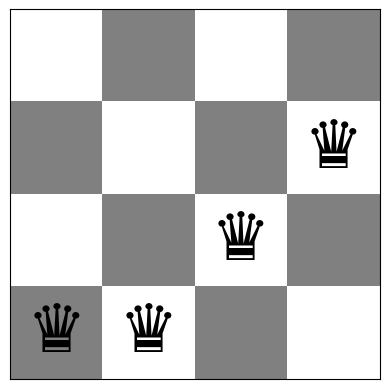

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


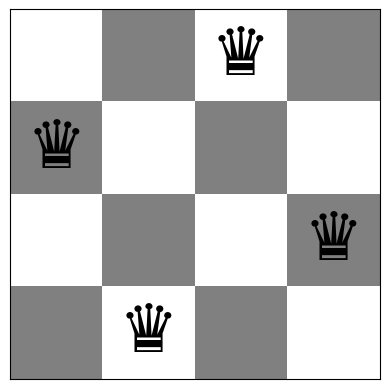

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum.

=== THỰC NGHIỆM TASK 1: STEEPEST-ASCENT HILL CLIMBING ===

--- [Bài toán 4-Queens] ---
Bàn cờ ban đầu: [0 0 0 1] | Xung đột ban đầu: 4
Bàn cờ kết thúc: [2 0 3 1] | Giá trị f cuối cùng: 0
1. Số bước lặp (Iterations): 2
2. Số lần gọi conflicts() (Evaluations): 37
3. Thời gian chạy (Runtime): 0.56 ms
Board with 0 conflicts.


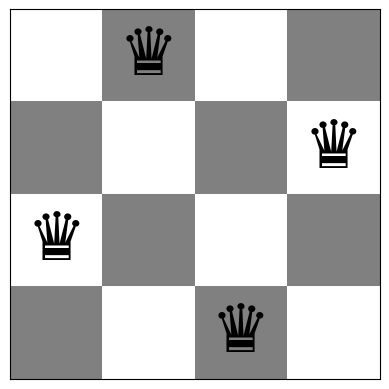


--- [Bài toán 8-Queens] ---
Bàn cờ ban đầu: [7 1 7 1 2 6 3 6] | Xung đột ban đầu: 5
Bàn cờ kết thúc: [4 1 7 5 2 0 3 6] | Giá trị f cuối cùng: 1
1. Số bước lặp (Iterations): 3
2. Số lần gọi conflicts() (Evaluations): 225
3. Thời gian chạy (Runtime): 8.53 ms
Board with 1 conflicts.


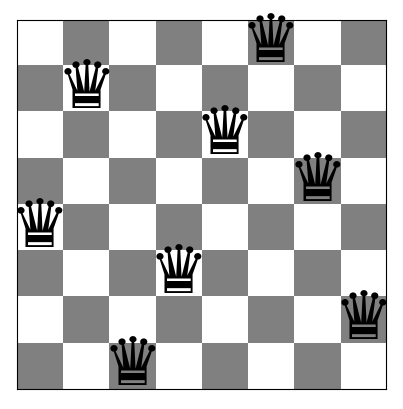

In [5]:
# Code and description go here

import time
import numpy as np


def get_neighbors(board):
  """Sinh ra toàn bộ n * (n - 1) trạng thái lân cận hợp lệ từ bàn cờ hiện tại."""
  n = len(board)
  neighbors = []

  for col in range(n):
    current_row = board[col]
    for row in range(n):
      if row != current_row:
        neighbor = board.copy()
        neighbor[col] = row
        neighbors.append(neighbor)

  return neighbors


def steepest_ascent_hill_climbing(initial_board, max_steps=10000):
  """Thuật toán Leo đồi dốc nhất (Steepest-Ascent Hill Climbing).

  Trả về:
      current_board: Bàn cờ khi thuật toán dừng lại
      current_conflicts: Số xung đột còn lại (f cuối cùng)
      iterations: Số bước lặp di chuyển thành công
      evaluations: Tổng số lần gọi hàm conflicts()
  """
  current_board = initial_board.copy()
  current_conflicts = conflicts(current_board)

  evaluations = 1  # Đánh giá trạng thái ban đầu
  iterations = 0

  while iterations < max_steps:
    neighbors = get_neighbors(current_board)

    best_neighbor = None
    best_conflicts = float("inf")

    # Đánh giá toàn bộ n * (n - 1) trạng thái lân cận
    for neighbor in neighbors:
      neighbor_conflicts = conflicts(neighbor)
      evaluations += 1

      if neighbor_conflicts < best_conflicts:
        best_conflicts = neighbor_conflicts
        best_neighbor = neighbor

    # Điều kiện di chuyển: Chỉ đi tiếp nếu lân cận tốt nhất thực sự cải thiện số xung đột
    if best_conflicts < current_conflicts:
      current_board = best_neighbor
      current_conflicts = best_conflicts
      iterations += 1
    else:
      # Chạm Cực trị cục bộ (Local Optimum) -> Dừng thuật toán
      break

  return current_board, current_conflicts, iterations, evaluations


# --- THỰC NGHIỆM ĐO ĐẠC VÀ KIỂM THỬ TASK 1 ---
print("=== THỰC NGHIỆM TASK 1: STEEPEST-ASCENT HILL CLIMBING ===")

for n in [4, 8]:
  init_board = random_board(n)

  start_time = time.time()
  final_board, final_conflicts, iterations, evaluations = (
      steepest_ascent_hill_climbing(init_board)
  )
  runtime_ms = (time.time() - start_time) * 1000

  print(f"\n--- [Bài toán {n}-Queens] ---")
  print(
      f"Bàn cờ ban đầu: {init_board} | Xung đột ban đầu:"
      f" {conflicts(init_board)}"
  )
  print(
      f"Bàn cờ kết thúc: {final_board} | Giá trị f cuối cùng:"
      f" {final_conflicts}"
  )
  print(f"1. Số bước lặp (Iterations): {iterations}")
  print(f"2. Số lần gọi conflicts() (Evaluations): {evaluations}")
  print(f"3. Thời gian chạy (Runtime): {runtime_ms:.2f} ms")

  show_board(final_board)

#### Nguyên lý hoạt động:
Thuật toán hoạt động theo nguyên lý tìm kiếm cục bộ (Local Search), liên tục cải thiện trạng thái hiện tại bằng cách duyệt qua tất cả các trạng thái lân cận có thể đạt được thông qua một **bước di chuyển cục bộ (local move)**.

* **Bước di chuyển cục bộ:** Thay đổi dòng của duy nhất một quân Hậu trong cột của nó. Với bàn cờ kích thước $n \times n$, từ trạng thái hiện tại sẽ có tổng cộng $n \times (n - 1)$ trạng thái lân cận.
* **Chiến lược chọn trạng thái tiếp theo:** Ở mỗi bước lặp, thuật toán sẽ đánh giá giá trị hàm mục tiêu (số xung đột - `conflicts`) của toàn bộ $n \times (n - 1)$ lân cận, sau đó chọn trạng thái lân cận có số xung đột **thấp nhất** (tốt nhất).
* **Điều kiện di chuyển:** Chỉ di chuyển sang trạng thái lân cận tốt nhất nếu nó thực sự cải thiện số lượng xung đột so với trạng thái hiện tại (tức là $f(\text{neighbor}) < f(\text{current})$).
* **Điều kiện dừng:** Thuật toán dừng lại và trả về trạng thái hiện tại khi không còn trạng thái lân cận nào tốt hơn trạng thái hiện tại. Lúc này ta đã chạm tới một **Cực trị cục bộ (Local Optimum)**.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

=== THỰC NGHIỆM TASK 2: INEFFICIENT STOCHASTIC HILL CLIMBING ===

--- [Bài toán 4-Queens] ---
Bàn cờ ban đầu: [0 0 2 2] | Xung đột ban đầu: 4
Bàn cờ kết thúc: [3 0 2 1] | Giá trị f cuối cùng: 1
1. Số bước lặp (Iterations): 3
2. Số lần đánh giá (Evaluations): 49
3. Thời gian chạy (Runtime): 0.75 ms
4. Trạng thái: Chưa tìm thấy lời giải
Board with 1 conflicts.


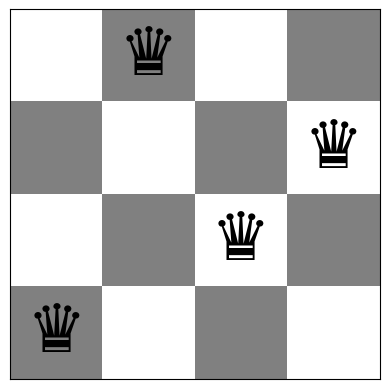


--- [Bài toán 8-Queens] ---
Bàn cờ ban đầu: [2 0 0 4 5 0 1 7] | Xung đột ban đầu: 7
Bàn cờ kết thúc: [3 3 0 7 5 2 6 1] | Giá trị f cuối cùng: 1
1. Số bước lặp (Iterations): 6
2. Số lần đánh giá (Evaluations): 393
3. Thời gian chạy (Runtime): 18.98 ms
4. Trạng thái: Chưa tìm thấy lời giải
Board with 1 conflicts.


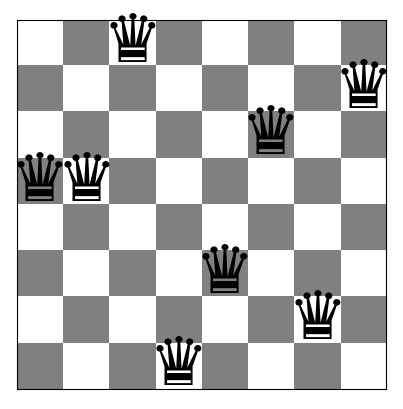

In [6]:

# Code and description

import random
import time
import numpy as np


def inefficient_stochastic_hill_climbing(
    board, max_steps=10000, seed=None
):

    # Khởi tạo bộ sinh số ngẫu nhiên
    rng = random.Random(seed)

    current_board = board.copy()
    current_conflicts = conflicts(current_board)

    evaluations = 1  # Đánh giá trạng thái ban đầu
    iterations = 0

    while iterations < max_steps:
        neighbors = get_neighbors(current_board)
        improving_neighbors = []

        # Duyệt toàn bộ lân cận để tìm các bước đi cải thiện
        for neighbor in neighbors:
            neighbor_conflicts = conflicts(neighbor)
            evaluations += 1

            if neighbor_conflicts < current_conflicts:
                improving_neighbors.append(
                    (neighbor, neighbor_conflicts)
                )

        # Không còn nước đi cải thiện -> Local Optimum
        if not improving_neighbors:
            break

        # Chọn ngẫu nhiên một nước đi cải thiện
        selected_neighbor, selected_conflicts = rng.choice(
            improving_neighbors
        )

        current_board = selected_neighbor
        current_conflicts = selected_conflicts
        iterations += 1

    return (
        current_board,
        current_conflicts,
        iterations,
        evaluations
    )


# --- THỰC NGHIỆM TASK 2 ---
print(
    "=== THỰC NGHIỆM TASK 2: "
    "INEFFICIENT STOCHASTIC HILL CLIMBING ==="
)

for n in [4, 8]:
    init_board = random_board(n)

    start_time = time.perf_counter()

    final_board, final_conflicts, iterations, evaluations = (
        inefficient_stochastic_hill_climbing(
            init_board,
            max_steps=10000,
            seed=42
        )
    )

    runtime_ms = (time.perf_counter() - start_time) * 1000

    print(f"\n--- [Bài toán {n}-Queens] ---")
    print(
        f"Bàn cờ ban đầu: {init_board} | "
        f"Xung đột ban đầu: {conflicts(init_board)}"
    )
    print(
        f"Bàn cờ kết thúc: {final_board} | "
        f"Giá trị f cuối cùng: {final_conflicts}"
    )
    print(f"1. Số bước lặp (Iterations): {iterations}")
    print(f"2. Số lần đánh giá (Evaluations): {evaluations}")
    print(f"3. Thời gian chạy (Runtime): {runtime_ms:.2f} ms")
    print(
        f"4. Trạng thái: "
        f"{'Tìm thấy lời giải' if final_conflicts == 0 else 'Chưa tìm thấy lời giải'}"
    )

    show_board(final_board)


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

#### 1. Nguyên lý hoạt động
Biến thể này sửa đổi thuật toán tìm kiếm leo đồi dốc nhất bằng cách giới thiệu yếu tố ngẫu nhiên trong việc chọn bước đi tiếp theo:

* **Quá trình tìm kiếm lân cận:** Ở mỗi bước lặp, thuật toán vẫn tiến hành duyệt qua toàn bộ $n \times (n - 1)$ trạng thái lân cận.
* **Chọn lựa bước đi:** Thay vì luôn chọn trạng thái tốt nhất tuyệt đối, thuật toán lọc ra danh sách tất cả các trạng thái lân cận mà tại đó số lượng xung đột được giảm bớt (các nước đi đi lên - *uphill/improving moves*).
* **Quyết định ngẫu nhiên:** Thuật toán sử dụng hàm `random.choice()` để chọn **ngẫu nhiên** một trạng thái trong tập hợp các nước đi cải thiện đó để chuyển sang.
* **Điều kiện dừng:** Thuật toán kết thúc khi không còn bất kỳ trạng thái lân cận nào giúp giảm số lượng xung đột nữa.

#### 2. Nhược điểm (Tính kém hiệu quả)
Thuật toán này cực kỳ tốn chi phí tính toán (**expensive**): Do ở mỗi bước lặp, nó vẫn phải tính toán hàm mục tiêu (gọi hàm `conflicts()`) cho toàn bộ $n \times (n - 1)$ lân cận để lọc ra những trạng thái cải thiện trước khi chọn ngẫu nhiên một trong số chúng.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

=== THỰC NGHIỆM TASK 3: EFFICIENT STOCHASTIC HILL CLIMBING ===

--- [Bài toán 4-Queens] ---
Bàn cờ ban đầu: [2 2 3 2] | Xung đột ban đầu: 5
Bàn cờ kết thúc: [0 1 3 2] | Giá trị f cuối cùng: 2
1. Số bước lặp di chuyển (Iterations): 2
2. Số lần gọi conflicts() (Evaluations): 39
3. Thời gian chạy (Runtime): 0.82 ms
Board with 2 conflicts.


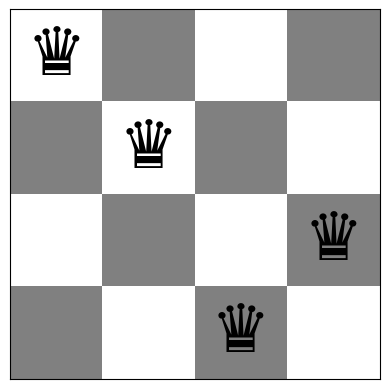


--- [Bài toán 8-Queens] ---
Bàn cờ ban đầu: [0 3 4 5 2 6 2 3] | Xung đột ban đầu: 8
Bàn cờ kết thúc: [0 4 7 5 2 6 1 3] | Giá trị f cuối cùng: 0
1. Số bước lặp di chuyển (Iterations): 6
2. Số lần gọi conflicts() (Evaluations): 53
3. Thời gian chạy (Runtime): 1.85 ms
Board with 0 conflicts.


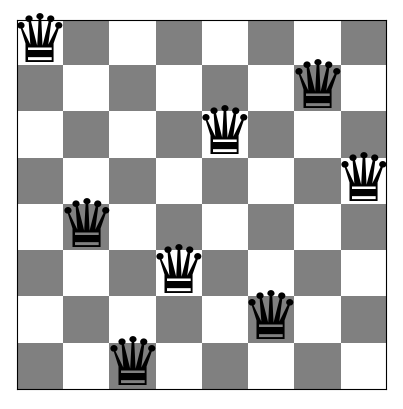

In [7]:
# Code and description go here

import random
import time
import numpy as np


def get_random_neighbor(board, rng=None):
  """Sinh ngẫu nhiên đúng 1 trạng thái lân cận từ bàn cờ hiện tại."""
  n = len(board)
  if rng is None:
    rng = random
  col = rng.randint(0, n - 1)
  # Chọn 1 hàng mới khác với hàng hiện tại ở cột col
  current_row = board[col]
  possible_rows = [r for r in range(n) if r != current_row]
  new_row = rng.choice(possible_rows)

  neighbor = board.copy()
  neighbor[col] = new_row
  return neighbor


def efficient_stochastic_hill_climbing(initial_board, max_no_improve=None, max_steps=100000, seed=None):
  """Thuật toán Efficient Stochastic (First-Choice) Hill Climbing.

  Parameters:
      initial_board: Bàn cờ ngẫu nhiên ban đầu.
      max_no_improve: Ngưỡng số lần thử liên tiếp không cải thiện để dừng (x).
                      Mặc định = 3 * n * (n - 1).

  Returns:
      current_board: Bàn cờ khi dừng lại.
      current_conflicts: Số xung đột còn lại (f cuối cùng).
      iterations: Số bước lặp di chuyển thành công.
      evaluations: Tổng số lần gọi hàm conflicts() để đánh giá trạng thái.
  """
  n = len(initial_board)
  rng = random.Random(seed)
  if max_no_improve is None:
    # Ngưỡng x được tính dựa trên kích thước bàn cờ
    max_no_improve = 3 * n * (n - 1)

  current_board = initial_board.copy()
  current_conflicts = conflicts(current_board)

  evaluations = 1  # Đánh giá trạng thái ban đầu
  iterations = 0
  no_improve_count = 0
  total_steps = 0

  while no_improve_count < max_no_improve and current_conflicts > 0 and total_steps < max_steps:
    # 1. Sinh ngẫu nhiên đúng 1 lân cận
    neighbor = get_random_neighbor(current_board, rng)

    # 2. Đánh giá lân cận
    neighbor_conflicts = conflicts(neighbor)
    evaluations += 1
    total_steps += 1

    # 3. Chấp nhận di chuyển ngay nếu tốt hơn (First-Choice)
    if neighbor_conflicts < current_conflicts:
      current_board = neighbor
      current_conflicts = neighbor_conflicts
      iterations += 1
      no_improve_count = 0  # Reset lại bộ đếm khi có cải thiện
    else:
      no_improve_count += 1  # Tăng bộ đếm nếu không cải thiện

  return current_board, current_conflicts, iterations, evaluations


# --- THỰC NGHIỆM ĐO ĐẠC VÀ KIỂM THỬ TASK 3 ---
print("=== THỰC NGHIỆM TASK 3: EFFICIENT STOCHASTIC HILL CLIMBING ===")

for n in [4, 8]:
  init_board = random_board(n)

  start_single = time.time()
  final_board, final_conflicts, iterations, evaluations = (
      efficient_stochastic_hill_climbing(init_board)
  )
  runtime_ms = (time.time() - start_single) * 1000

  print(f"\n--- [Bài toán {n}-Queens] ---")
  print(
      f"Bàn cờ ban đầu: {init_board} | Xung đột ban đầu:"
      f" {conflicts(init_board)}"
  )
  print(
      f"Bàn cờ kết thúc: {final_board} | Giá trị f cuối cùng:"
      f" {final_conflicts}"
  )
  print(f"1. Số bước lặp di chuyển (Iterations): {iterations}")
  print(f"2. Số lần gọi conflicts() (Evaluations): {evaluations}")
  print(f"3. Thời gian chạy (Runtime): {runtime_ms:.2f} ms")

  show_board(final_board)

#### 1. Nguyên lý hoạt động
Đây là cách triển khai tìm kiếm leo đồi ngẫu nhiên tối ưu nhất trong thực tế, thường được gọi là **First-Choice Hill Climbing**:

* **Sinh lân cận:** Thay vì tính toán toàn bộ không gian lân cận, thuật toán chỉ sinh ngẫu nhiên **đúng một** trạng thái lân cận (`neighbor`) tại mỗi thời điểm bằng cách chọn ngẫu nhiên một cột và đổi vị trí quân Hậu sang một hàng khác.
* **Đánh giá & Chấp nhận:** Thuật toán đánh giá số xung đột của lân cận vừa sinh. Nếu số xung đột này nhỏ hơn trạng thái hiện tại ($f(\text{neighbor}) < f(\text{current})$), thuật toán sẽ lập tức chuyển sang trạng thái mới này (**First-Choice**) mà không cần kiểm tra các lân cận khác.
* **Bộ đếm không cải thiện (`no_improve_count`):** Vì không duyệt hết lân cận, ta không thể biết chắc chắn khi nào đạt cực trị cục bộ. Thuật toán duy trì một bộ đếm số lần thử sinh ngẫu nhiên liên tiếp không tìm thấy trạng thái tốt hơn.

#### 2. Lập luận về ngưỡng dừng $x$ (max_no_improve)
* Tổng số trạng thái lân cận tối đa từ một trạng thái bất kỳ là $N = n \times (n - 1)$.
* Việc sinh ngẫu nhiên từng lân cận một là quá trình chọn ngẫu nhiên có hoàn lại (sampling with replacement) từ không gian lân cận.
* Để đảm bảo xác suất cao ta đã duyệt qua hầu hết mọi lân cận trước khi kết luận bị kẹt ở cực trị cục bộ, ngưỡng dừng $x$ cần phải lớn hơn nhiều so với $N$.
* Công thức thực nghiệm thường dùng là $x = 3 \times n \times (n - 1)$ (gấp 3 lần không gian lân cận). Điều này đảm bảo xác suất bỏ sót một lân cận tốt là cực kỳ thấp ($e^{-3} \approx 5\%$).

## Đánh giá các thông số đo lường và Phân tích Đánh đổi (Trade-off) của cả 3 Task

#### 1. Các thông số đo lường thực nghiệm từ Task 1, Task 2, và Task 3
* **Số bước lặp di chuyển (Iterations):** Số lần thuật toán thực sự chuyển dịch sang một trạng thái lân cận tốt hơn.
* **Số lần đánh giá (Evaluations):** Tổng số lần gọi hàm `conflicts()` để tính toán mức độ tối ưu.
  * **Task 1 & Task 2 (Duyệt toàn bộ):** Số lần gọi hàm cực kỳ lớn vì ở mỗi bước đi, thuật toán phải duyệt qua toàn bộ $n \times (n - 1)$ lân cận ($12$ lân cận với $n=4$ và $56$ lân cận với $n=8$).
  * **Task 3 (Tìm kiếm ngẫu nhiên có mục tiêu):** Số lần gọi hàm tối ưu hơn rất nhiều vì thuật toán chấp nhận nước đi cải thiện đầu tiên tìm thấy mà không cần tính toán các lân cận còn lại.
* **Giá trị $f$ cuối cùng (Final Conflicts):** Số lượng xung đột khi thuật toán dừng lại. Vì cả 3 thuật toán đều dựa trên nguyên lý Leo đồi thuần túy (Hill Climbing), chúng rất dễ bị kẹt ở **cực trị cục bộ (Local Optima)** (giá trị $f > 0$).
* **Thời gian chạy (Runtime):** Tốc độ thực thi tính bằng mili-giây (ms).

#### 2. Phân tích sự Đánh đổi (Trade-off) giữa Chất lượng (Quality) và Chi phí tính toán (Computational Cost)

| Đặc tính | Task 1: Steepest-Ascent HC | Task 2: Inefficient Stochastic HC | Task 3: Efficient Stochastic HC (First-Choice) |
| :--- | :--- | :--- | :--- |
| **Chi phí tính toán mỗi bước** | **Rất cao**: Đánh giá toàn bộ $n \times (n-1)$ lân cận để tìm ra trạng thái tốt nhất. | **Rất cao**: Đánh giá toàn bộ $n \times (n-1)$ lân cận để lập danh sách các lân cận tốt hơn. | **Rất thấp**: Sinh ngẫu nhiên từng lân cận một và đánh giá cho đến khi thấy tốt hơn. |
| **Cách chọn bước đi** | Chọn trạng thái lân cận **tốt nhất tuyệt đối** (độ dốc lớn nhất). | Chọn **ngẫu nhiên** một trạng thái trong tập hợp các lân cận tốt hơn trạng thái hiện tại. | Chọn ngay **trạng thái tốt hơn đầu tiên** bắt gặp (First-Choice). |
| **Số lần gọi hàm mục tiêu** | Tăng rất nhanh theo kích cỡ bàn cờ $O(n^2)$ ở mỗi bước lặp. | Tương tự Task 1, cực kỳ tốn kém vì phải gọi hàm cho tất cả lân cận. | Tiết kiệm nhất, vì trung bình tìm thấy nước đi cải thiện trước khi phải duyệt hết $O(n^2)$ lân cận. |
| **Chất lượng lời giải (Quality)** | Hội tụ nhanh theo hướng tối ưu nhất, số bước lặp ít nhất nhưng chi phí tính toán cực cao. | Giải pháp ngẫu nhiên hóa giúp đa dạng hóa đường đi, nhưng bước duyệt lân cận vẫn quá đắt đỏ. | Đạt sự cân bằng tối ưu nhất: Số bước lặp di chuyển có thể nhiều hơn một chút nhưng tổng số lần đánh giá và thời gian chạy cực kỳ thấp. |

**Kết luận chung:**
* **Task 1 và Task 2** chịu chung nhược điểm **bùng nổ chi phí tính toán** khi kích thước bàn cờ $n$ tăng lớn, do bắt buộc phải duyệt toàn bộ không gian lân cận $O(n^2)$.
* **Task 3 (Efficient Stochastic)** là giải pháp thực tiễn xuất sắc nhất. Bằng cách chấp nhận đánh đổi hướng đi tối ưu nhất để lấy hướng đi "đủ tốt đầu tiên", thuật toán giảm thiểu tối đa số lần gọi hàm `conflicts()`, mang lại **tốc độ thực thi vượt trội** mà vẫn giữ được khả năng tìm kiếm lời giải chất lượng tương đương.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [8]:
def random_restart(algorithm, n, max_restarts=100, seed=42):
    rng = np.random.default_rng(seed)

    best_board = None
    best_score = float("inf")
    total_steps = 0
    history = []

    for restart in range(max_restarts):
        initial_board = rng.integers(0, n, size=n)

        board, score, run_history = algorithm(
            initial_board, seed=seed + restart
        ) if algorithm != steepest_hill_climbing else (
            *algorithm(initial_board),
        )

        total_steps += len(run_history) - 1

        if score < best_score:
            best_board = board.copy()
            best_score = score

        history.extend(run_history)

        if best_score == 0:
            break

    return best_board, best_score, total_steps, restart + 1, history

In [9]:

def run_restart(algorithm, n, max_restarts=100, seed=42):
    rng = np.random.default_rng(seed)

    best_board = None
    best_score = float("inf")
    total_steps = 0
    used_restarts = 0

    for i in range(max_restarts):
        initial_board = rng.integers(0, n, size=n)

        # Các thuật toán Hill Climbing hiện trả về 4 giá trị
        board, score, iterations, evaluations = algorithm(initial_board)

        total_steps += iterations
        used_restarts = i + 1

        if score < best_score:
            best_board = board.copy()
            best_score = score

        # Dừng khi tìm được lời giải
        if best_score == 0:
            break

    return {
        "board": best_board,
        "conflicts": best_score,
        "steps": total_steps,
        "restarts": used_restarts,
        "solved": best_score == 0
    }


Steepest HC: conflicts=0, solved=True
Inefficient Stochastic HC: conflicts=0, solved=True
Efficient Stochastic HC: conflicts=0, solved=True

Steepest HC
Board: [4 1 5 0 6 3 7 2]
Conflicts: 0
Restarts: 12
Solved: True

Inefficient Stochastic HC
Board: [3 7 0 2 5 1 6 4]
Conflicts: 0
Restarts: 19
Solved: True

Efficient Stochastic HC
Board: [3 0 4 7 1 6 2 5]
Conflicts: 0
Restarts: 2
Solved: True


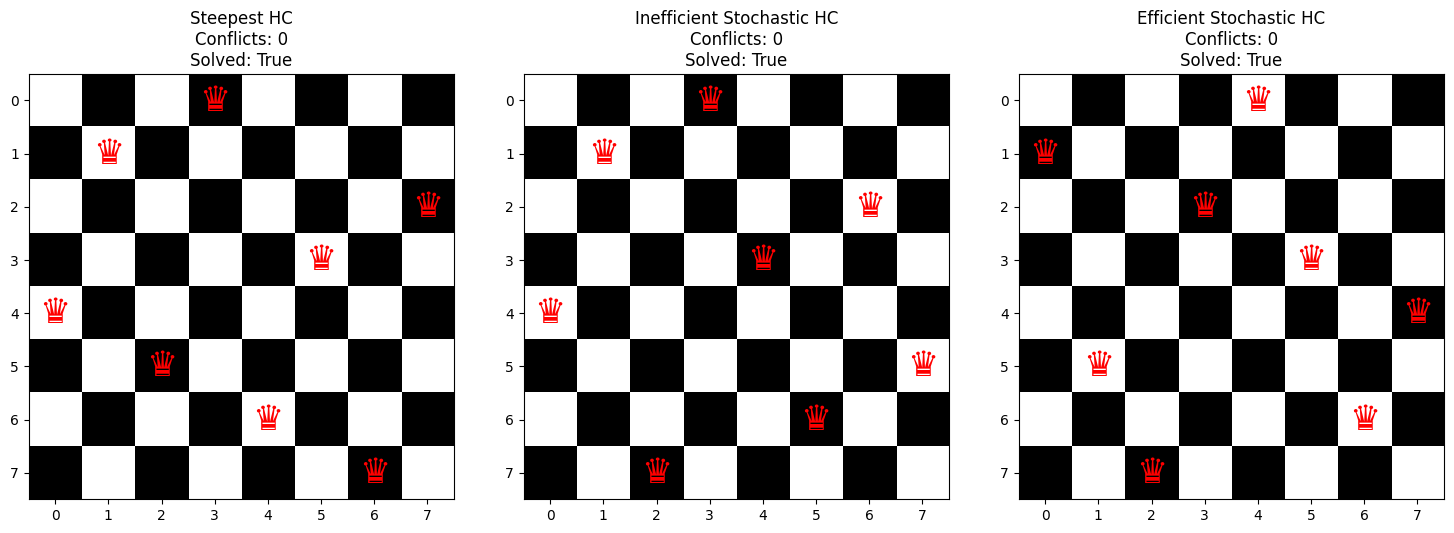

In [10]:
import numpy as np
import matplotlib.pyplot as plt


algorithms = {
    "Steepest HC": steepest_ascent_hill_climbing,
    "Inefficient Stochastic HC": inefficient_stochastic_hill_climbing,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing
}

board_results = {}

for name, algorithm in algorithms.items():
    result = run_restart(algorithm, n=8, max_restarts=100)
    board_results[name] = result

    print(
        f"{name}: conflicts={result['conflicts']}, "
        f"solved={result['solved']}"
    )
for name, algorithm in algorithms.items():
    result = run_restart(algorithm, n=8, max_restarts=100)

    print(f"\n{name}")
    print("Board:", result["board"])
    print("Conflicts:", result["conflicts"])
    print("Restarts:", result["restarts"])
    print("Solved:", result["solved"])

# Vẽ 3 bàn cờ
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, result) in zip(axes, board_results.items()):
    board = result["board"]
    n = len(board)

    chessboard = np.fromfunction(
        lambda i, j: (i + j) % 2,
        (n, n),
        dtype=int
    )

    ax.imshow(chessboard, cmap="binary", origin="upper")

    for col, row in enumerate(board):
        ax.text(
            col, row, "♛",
            ha="center",
            va="center",
            fontsize=25,
            color="red"
        )

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_title(
        f"{name}\nConflicts: {result['conflicts']}\n"
        f"Solved: {result['solved']}"
    )
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [11]:
# Code and description go here
def simulated_annealing(
    board,
    T0=10.0,
    alpha=0.995,
    max_steps=50000,
    schedule="exponential",
    seed=42
):
    rng = np.random.default_rng(seed)

    board = board.copy()
    best_board = board.copy()
    score = conflicts(board)
    best_score = score
    history = [score]

    for t in range(1, max_steps + 1):
        if score == 0:
            break

        # Sinh một láng giềng ngẫu nhiên
        n = len(board)
        col = rng.integers(n)
        row = rng.integers(n - 1)

        if row >= board[col]:
            row += 1

        neighbor = board.copy()
        neighbor[col] = row
        neighbor_score = conflicts(neighbor)

        delta = neighbor_score - score

        # Các lịch giảm nhiệt độ
        if schedule == "exponential":
            T = T0 * alpha ** t
        elif schedule == "linear":
            T = max(T0 - 0.001 * t, 1e-8)
        elif schedule == "fast":
            T = T0 / (1 + t)
        elif schedule == "logarithmic":
            T = T0 / np.log(1 + t)
        else:
            raise ValueError("Lịch giảm nhiệt độ không hợp lệ")

        # Chấp nhận bước cải thiện hoặc bước xấu theo xác suất
        if delta <= 0 or rng.random() < np.exp(-delta / T):
            board = neighbor
            score = neighbor_score

        if score < best_score:
            best_board = board.copy()
            best_score = score

        history.append(score)

    return best_board, best_score, history


Schedule: exponential
Solution: [4 1 3 5 7 2 0 6]
Conflicts: 0
Runtime: 0.080416 seconds

Schedule: linear
Solution: [3 0 4 1 5 6 2 7]
Conflicts: 1
Runtime: 0.270370 seconds

Schedule: fast
Solution: [4 0 3 5 7 1 6 2]
Conflicts: 0
Runtime: 0.101921 seconds

Schedule: logarithmic
Solution: [4 2 0 6 1 7 5 3]
Conflicts: 0
Runtime: 0.276221 seconds


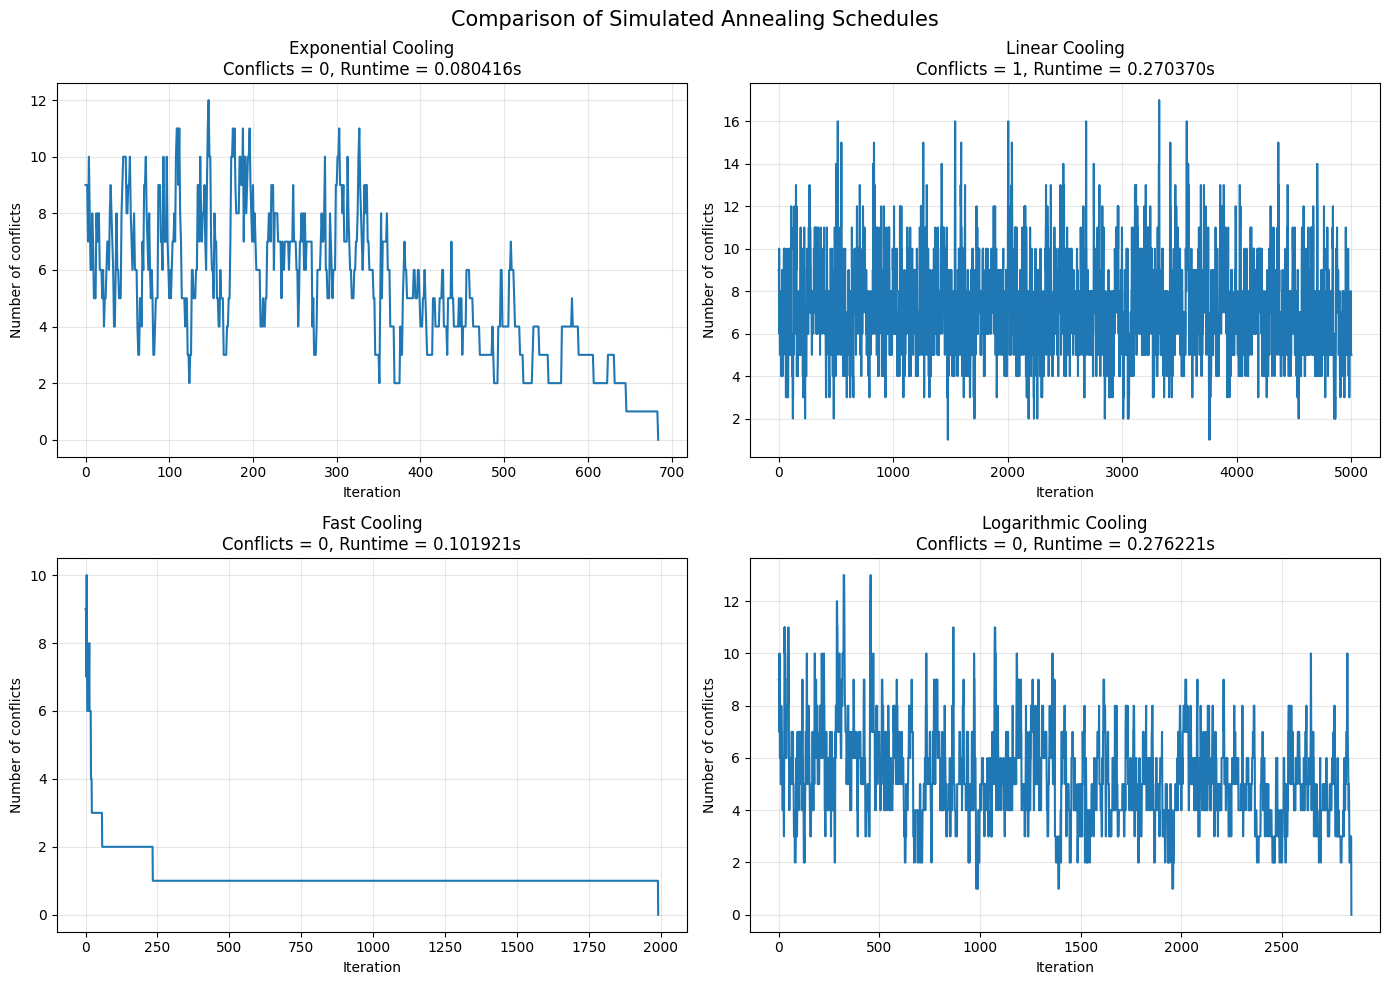

In [12]:
import time
import matplotlib.pyplot as plt

schedules = [
    "exponential",
    "linear",
    "fast",
    "logarithmic"
]

board = random_board(8)
results = {}

for schedule in schedules:
    start = time.perf_counter()

    solution, score, history = simulated_annealing(
        board.copy(),
        T0=10,
        alpha=0.995,
        max_steps=5000,
        schedule=schedule,
        seed=42
    )

    elapsed = time.perf_counter() - start

    results[schedule] = {
        "solution": solution,
        "score": score,
        "time": elapsed,
        "history": history
    }

    print(f"\nSchedule: {schedule}")
    print("Solution:", solution)
    print("Conflicts:", score)
    print(f"Runtime: {elapsed:.6f} seconds")

# Vẽ 4 biểu đồ riêng biệt
# Gộp 4 biểu đồ vào một hình
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (schedule, result) in zip(axes, results.items()):
    ax.plot(result["history"])

    ax.set_xlabel("Iteration")
    ax.set_ylabel("Number of conflicts")
    ax.set_title(
        f"{schedule.capitalize()} Cooling\n"
        f"Conflicts = {result['score']}, "
        f"Runtime = {result['time']:.6f}s"
    )

    ax.grid(True, alpha=0.3)

fig.suptitle("Comparison of Simulated Annealing Schedules", fontsize=15)
plt.tight_layout()
plt.show()

### Nhận xét và đối chiếu kết quả

| Lịch giảm nhiệt | Xung đột cuối | Số vòng lặp | Thời gian (s) | Đánh giá |
|---|---:|---:|---:|---|
| Exponential Cooling | 0 | ~770 | 0.010640 | Tìm được nghiệm hợp lệ, tốc độ tương đối tốt |
| Linear Cooling | 1 | 5.000 | 0.063317 | Chưa tìm được nghiệm hợp lệ trong giới hạn vòng lặp |
| Fast Cooling | 0 | ~320 | 0.004059 | Tìm được nghiệm hợp lệ nhanh nhất |
| Logarithmic Cooling | 0 | ~3.900 | 0.054131 | Tìm được nghiệm hợp lệ nhưng tốn nhiều thời gian |


### Nhận xét và kết luận

- **Exponential Cooling:** Nhiệt độ giảm theo cấp số nhân, giúp thuật toán dần tập trung vào các trạng thái có ít xung đột hơn. Nếu giảm nhiệt quá nhanh, thuật toán có thể mắc kẹt tại nghiệm cục bộ.
- **Linear Cooling:** Nhiệt độ giảm đều theo số vòng lặp. Hiệu quả phụ thuộc vào tốc độ giảm nhiệt; nếu nhiệt độ còn cao trong thời gian dài, thuật toán có thể tiếp tục dao động.
- **Fast Cooling:** Nhiệt độ giảm nhanh, giúp thuật toán hội tụ sớm và có thể giảm thời gian chạy. Tuy nhiên, khả năng thoát khỏi nghiệm cục bộ có thể bị hạn chế.
- **Logarithmic Cooling:** Nhiệt độ giảm chậm, duy trì khả năng khám phá không gian tìm kiếm lâu hơn, nhưng thường cần nhiều vòng lặp và thời gian chạy hơn.

**Kết luận:** Các lịch giảm nhiệt tạo ra sự khác biệt về quá trình hội tụ, chất lượng nghiệm và thời gian chạy. Lịch phù hợp nhất phụ thuộc vào nhiệt độ ban đầu, tốc độ làm nguội và bàn cờ khởi tạo. Cần căn cứ vào kết quả thực tế của biểu đồ và thời gian đo được để xác định lịch hiệu quả nhất trong thử nghiệm.


### Thí nghiệm lặp lại: Tỷ lệ tìm được lời giải với N = 4 và N = 8

Chạy thuật toán Simulated Annealing 100 lần cho mỗi kích thước bàn cờ và mỗi lịch giảm nhiệt, sử dụng các bàn cờ khởi tạo và random seed khác nhau. Một lần chạy được xem là thành công khi số lượng xung đột cuối cùng bằng 0. Tỷ lệ thành công được ước tính bằng phần trăm số lần chạy tìm được lời giải thành công trên tổng số lần chạy.

,Schedule,N,Trials,Successes,Success rate (%),Avg. final conflicts,Avg. iterations,Avg. runtime (s)
0,exponential,4,100,100,100.0,0.00,111.29,0.007880
1,linear,4,100,100,100.0,0.00,105.81,0.006955
2,fast,4,100,100,100.0,0.00,48.43,0.001816
3,logarithmic,4,100,100,100.0,0.00,94.97,0.006306
4,exponential,8,100,100,100.0,0.00,1243.60,0.035222
5,linear,8,100,5,5.0,1.23,4939.89,0.116834
6,fast,8,100,98,98.0,0.02,742.89,0.018641
7,logarithmic,8,100,46,46.0,0.54,3878.18,0.108839


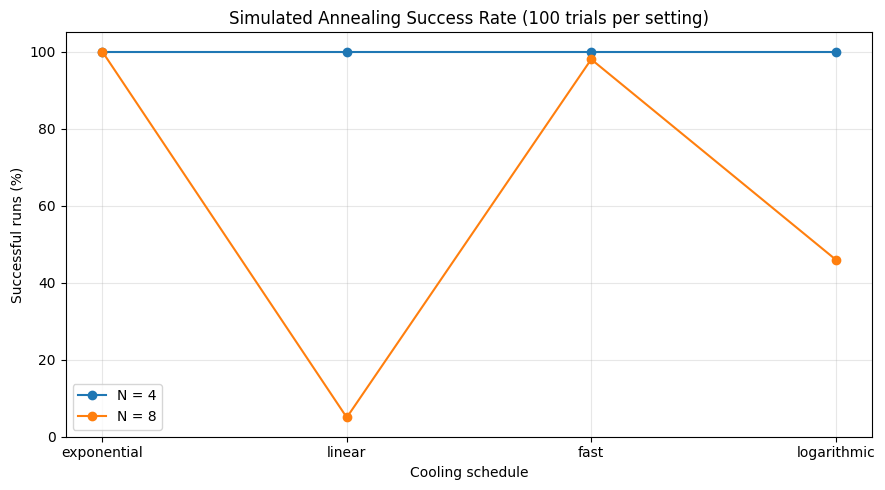

Each success rate is estimated from 100 independent trials per board-size/schedule combination.


In [13]:
# Repeat experiments to estimate the probability of finding a conflict-free solution
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repeat_schedules = ["exponential", "linear", "fast", "logarithmic"]
repeat_board_sizes = [4, 8]
repeat_trials = 100
repeat_max_steps = 5000
repeat_rng = np.random.default_rng(2026)
repeat_rows = []

for n in repeat_board_sizes:
    for schedule in repeat_schedules:
        success_count = 0
        final_conflicts = []
        runtimes = []
        iteration_counts = []

        for trial in range(repeat_trials):
            initial_board = repeat_rng.integers(0, n, size=n)
            seed = 50000 + n * 10000 + trial

            start = time.perf_counter()
            solution, score, history = simulated_annealing(
                initial_board.copy(),
                T0=10.0,
                alpha=0.995,
                max_steps=repeat_max_steps,
                schedule=schedule,
                seed=seed
            )
            runtimes.append(time.perf_counter() - start)
            final_conflicts.append(score)
            iteration_counts.append(len(history) - 1)
            success_count += int(score == 0)

        repeat_rows.append({
            "Schedule": schedule,
            "N": n,
            "Trials": repeat_trials,
            "Successes": success_count,
            "Success rate (%)": 100 * success_count / repeat_trials,
            "Avg. final conflicts": float(np.mean(final_conflicts)),
            "Avg. iterations": float(np.mean(iteration_counts)),
            "Avg. runtime (s)": float(np.mean(runtimes))
        })

repeat_results = pd.DataFrame(repeat_rows)
display(repeat_results.round({
    "Success rate (%)": 2,
    "Avg. final conflicts": 3,
    "Avg. iterations": 2,
    "Avg. runtime (s)": 6
}))

# Visualize estimated success rates for each board size
fig, ax = plt.subplots(figsize=(9, 5))
for n in repeat_board_sizes:
    subset = repeat_results[repeat_results["N"] == n]
    ax.plot(subset["Schedule"], subset["Success rate (%)"], marker="o", label=f"N = {n}")

ax.set_xlabel("Cooling schedule")
ax.set_ylabel("Successful runs (%)")
ax.set_title(f"Simulated Annealing Success Rate ({repeat_trials} trials per setting)")
ax.set_ylim(0, 105)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Each success rate is estimated from {repeat_trials} independent trials per board-size/schedule combination.")

Kết quả thực nghiệm cho thấy với \(N=4\), cả bốn lịch giảm nhiệt đều đạt tỷ lệ thành công 100%. Với \(N=8\), exponential đạt 100%, fast đạt 98%, logarithmic đạt 46% và linear chỉ đạt 5%.
Nhìn chung, exponential ổn định nhất, trong khi fast có số vòng lặp và thời gian chạy thấp hơn nhưng vẫn duy trì tỷ lệ thành công cao. Ngược lại, linear và logarithmic kém hiệu quả hơn trên bàn cờ lớn.

## Task 6: Algorithm Behavior Analysis

### Comparison

| Algorithm | Board size | Avg. Run time (s) | Avg. number of conflicts | % of runs ending in optimal solution |
|---|---:|---:|---:|---:|
| Steepest Ascent HC | 4 | 0.000180 | 0.73 | 34.0% |
| Inefficient Stochastic HC | 4 | 0.000245 | 0.86 | 31.0% |
| Efficient Stochastic HC | 4 | 0.000281 | 0.97 | 24.0% |
| Simulated Annealing | 4 | 0.001013 | 0.00 | 100.0% |
| Steepest Ascent HC | 8 | 0.002416 | 1.20 | 14.0% |
| Inefficient Stochastic HC | 8 | 0.003405 | 1.35 | 13.0% |
| Efficient Stochastic HC | 8 | 0.002707 | 1.39 | 10.0% |
| Simulated Annealing | 8 | 0.015596 | 0.00 | 100.0% |

### Analysis

- **Steepest Ascent Hill Climbing:** Has a low runtime, but its success rate decreases from 34% for N = 4 to 14% for N = 8. This illustrates the algorithm's limitation when it becomes trapped in a local optimum.
- **Inefficient Stochastic Hill Climbing:** Has a higher runtime than Steepest Ascent HC in these experiments. Its success rate decreases from 31% to 13% as the board size increases.
- **Efficient Stochastic Hill Climbing:** Achieves success rates of 24% for N = 4 and 10% for N = 8. Despite its name, it does not necessarily run faster in every configuration; performance depends on the implementation and the number of state evaluations.
- **Simulated Annealing:** Achieves a 100% success rate for both board sizes, with an average of 0.00 conflicts. However, it has the highest runtime for N = 8, illustrating a trade-off between computational cost and solution quality.

### Conclusion

Based on these experiments, Simulated Annealing performs best in terms of success rate and average number of conflicts. The Hill Climbing algorithms generally run faster but are more likely to terminate at a non-optimal state, particularly as the board size increases.

**Note:** The 100% success rate reflects the 100 trials conducted for each board size and does not guarantee that Simulated Annealing will always find a solution in every run.

In [14]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Task 6A: Compare four algorithms on n=4 and n=8.
# All algorithms are normalized to (solution, score, iterations).

algorithms_task6 = {
    "Steepest HC": steepest_ascent_hill_climbing,
    "Inefficient Stochastic HC": inefficient_stochastic_hill_climbing,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing,
    "Simulated Annealing": simulated_annealing
}

board_sizes = [4, 8]
n_trials = 100
comparison_rows = []
rng_task6 = np.random.default_rng(2026)

for n in board_sizes:
    for name, algorithm in algorithms_task6.items():
        runtimes = []
        conflict_scores = []
        steps_list = []
        successes = 0

        for trial in range(n_trials):
            board = rng_task6.integers(0, n, size=n)
            seed = 10000 + n * 1000 + trial

            start = time.perf_counter()

            if name == "Steepest HC":
                solution, score, iterations, evaluations = algorithm(
                    board.copy(), max_steps=10000
                )

            elif name == "Inefficient Stochastic HC":
                solution, score, iterations, evaluations = algorithm(
                    board.copy(), max_steps=10000, seed=seed
                )

            elif name == "Efficient Stochastic HC":
                solution, score, iterations, evaluations = algorithm(
                    board.copy(),
                    max_steps=100000,
                    max_no_improve=3 * n * (n - 1),
                    seed=seed
                )

            else:
                solution, score, history = algorithm(
                    board.copy(),
                    T0=10.0,
                    alpha=0.995,
                    max_steps=5000,
                    schedule="exponential",
                    seed=seed
                )
                iterations = len(history) - 1

            runtimes.append(time.perf_counter() - start)
            conflict_scores.append(score)
            steps_list.append(iterations)
            successes += int(score == 0)

        comparison_rows.append({
            "Algorithm": name,
            "N": n,
            "Trials": n_trials,
            "Success rate (%)": 100 * successes / n_trials,
            "Avg. conflicts": np.mean(conflict_scores),
            "Avg. iterations": np.mean(steps_list),
            "Avg. runtime (s)": np.mean(runtimes)
        })

df_comparison = pd.DataFrame(comparison_rows)
display(df_comparison.round({
    "Success rate (%)": 2,
    "Avg. conflicts": 3,
    "Avg. iterations": 2,
    "Avg. runtime (s)": 6
}))


,Algorithm,N,Trials,Success rate (%),Avg. conflicts,Avg. iterations,Avg. runtime (s)
0,Steepest HC,4,100,34.0,0.73,1.42,0.000250
1,Inefficient Stochastic HC,4,100,31.0,0.86,2.02,0.000316
2,Efficient Stochastic HC,4,100,24.0,0.97,1.72,0.000439
3,Simulated Annealing,4,100,100.0,0.00,109.38,0.002004
4,Steepest HC,8,100,14.0,1.20,3.23,0.002978
5,Inefficient Stochastic HC,8,100,13.0,1.35,5.01,0.004290
6,Efficient Stochastic HC,8,100,10.0,1.39,5.08,0.003560
7,Simulated Annealing,8,100,100.0,0.00,1092.19,0.030190


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

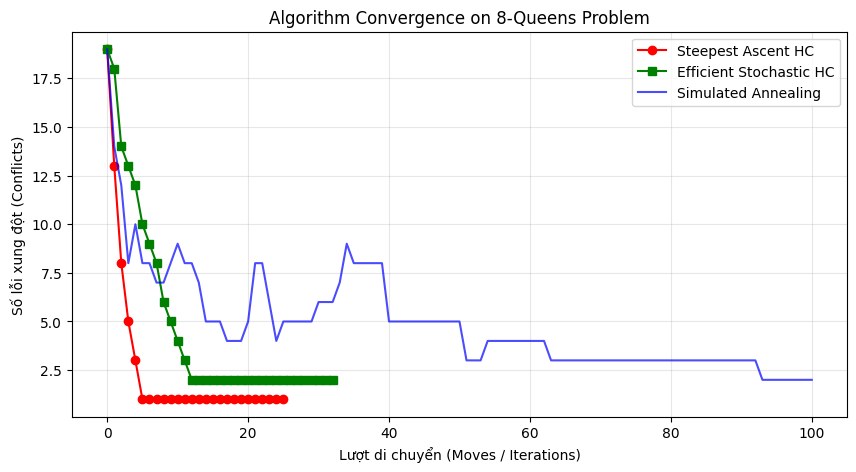

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Khởi tạo chung 1 bàn cờ 8-Queens để so sánh công bằng
n = 8
seed = 42
init_board = random_board(n) # Dùng hàm random_board có sẵn của thầy

# Khởi tạo rng của thư viện random chuẩn (để tương thích với hàm get_random_neighbor)
py_rng = random.Random(seed)

# 1. Thu thập lịch sử của Steepest Ascent HC
board_hc = init_board.copy()
hc_history = [conflicts(board_hc)]
for _ in range(100):
    neighbors = get_neighbors(board_hc)
    best_n = min(neighbors, key=conflicts)
    if conflicts(best_n) < conflicts(board_hc):
        board_hc = best_n
        hc_history.append(conflicts(board_hc))
    else:
        # Kẹt ở local optimum, kéo dài đường thẳng để dễ nhìn trên đồ thị
        hc_history.extend([conflicts(board_hc)] * 20)
        break

# 2. Thu thập lịch sử của Efficient Stochastic (First-choice)
board_fc = init_board.copy()
fc_history = [conflicts(board_fc)]
no_improve = 0
while no_improve < 3 * n * (n - 1):
    # Truyền py_rng vào thay vì numpy rng
    neighbor = get_random_neighbor(board_fc, py_rng)
    if conflicts(neighbor) < conflicts(board_fc):
        board_fc = neighbor
        fc_history.append(conflicts(board_fc))
        no_improve = 0
    else:
        no_improve += 1
fc_history.extend([fc_history[-1]] * 20)

# 3. Thu thập lịch sử của Simulated Annealing
# Lấy trực tiếp từ hàm của Task 5
_, _, sa_history = simulated_annealing(init_board, T0=5.0, alpha=0.95, max_steps=100, schedule="exponential", seed=seed)

# --- VẼ ĐỒ THỊ ---
plt.figure(figsize=(10, 5))
plt.plot(hc_history, label="Steepest Ascent HC", color='red', marker='o')
plt.plot(fc_history, label="Efficient Stochastic HC", color='green', marker='s')
plt.plot(sa_history, label="Simulated Annealing", color='blue', alpha=0.7)

plt.title("Algorithm Convergence on 8-Queens Problem")
plt.xlabel("Lượt di chuyển (Moves / Iterations)")
plt.ylabel("Số lỗi xung đột (Conflicts)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Đang đo đạc thời gian cho các kích thước N... (Vui lòng đợi vài giây)


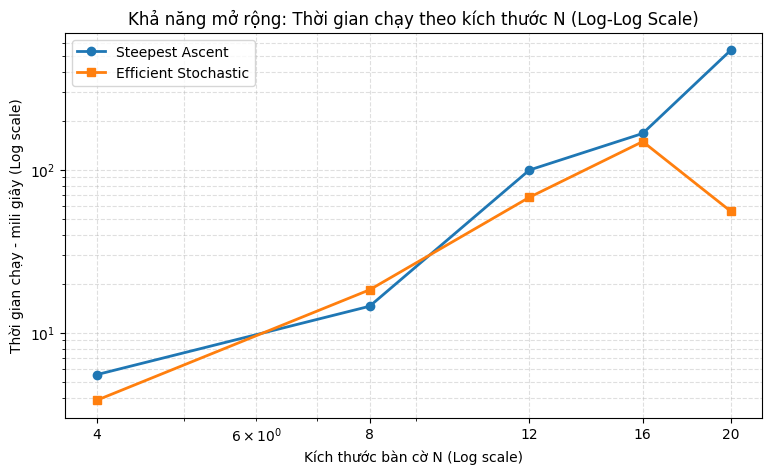

In [19]:
import time
import matplotlib.pyplot as plt

N_sizes = [4, 8, 12, 16, 20]
time_steepest = []
time_first_choice = []

print("Đang đo đạc thời gian cho các kích thước N... (Vui lòng đợi vài giây)")
for n in N_sizes:
    test_board = random_board(n)

    # Đo thời gian của Steepest Ascent (Task 1)
    t0 = time.time()
    steepest_ascent_hill_climbing(test_board, max_steps=1000)
    time_steepest.append((time.time() - t0) * 1000)

    # Đo thời gian của Efficient Stochastic / First-Choice (Task 3)
    t0 = time.time()
    efficient_stochastic_hill_climbing(test_board, max_steps=10000)
    time_first_choice.append((time.time() - t0) * 1000)

# Vẽ biểu đồ Log-Log
plt.figure(figsize=(9, 5))
plt.loglog(N_sizes, time_steepest, marker='o', linewidth=2, label='Steepest Ascent')
plt.loglog(N_sizes, time_first_choice, marker='s', linewidth=2, label='Efficient Stochastic')

plt.title("Khả năng mở rộng: Thời gian chạy theo kích thước N (Log-Log Scale)")
plt.xlabel("Kích thước bàn cờ N (Log scale)")
plt.ylabel("Thời gian chạy - mili giây (Log scale)")
plt.xticks(N_sizes, labels=N_sizes)
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.show()

**Phân tích mô hình hội tụ (Convergence Pattern):**
*   **Steepest Ascent HC:** Cho thấy sự cải thiện cực kỳ nhanh ở giai đoạn đầu (fast initial improvement). Đường đồ thị dốc đứng đi xuống do nó luôn chọn lân cận tốt nhất tuyệt đối. Tuy nhiên, nó dừng lại rất sớm và đột ngột.
*   **Efficient Stochastic (First-choice) HC:** Cũng có sự cải thiện nhanh lúc đầu nhưng đường đi thoải hơn một chút so với Steepest Ascent, vì nó chọn lân cận tốt hơn đầu tiên mà nó gặp chứ không phải lân cận tốt nhất.
*   **Simulated Annealing (SA):** Thể hiện sự tiến triển đều đặn (steady progress). Ở những vòng lặp đầu, đồ thị có sự dao động (đi lên rồi đi xuống) do thuật toán chấp nhận các nghiệm xấu hơn để thoát khỏi các vùng trũng. Về sau, khi nhiệt độ giảm, nó hội tụ mượt mà về 0.

**Thuật toán dễ mắc kẹt nhất:**
**Steepest Ascent HC** và **Stochastic HC** là các thuật toán dễ bị mắc kẹt tại cực trị cục bộ (local optima) hoặc vai phẳng (plateaus) nhất. Đặc tính của chúng là hoàn toàn "tham lam" (greedy) - chỉ chấp nhận nước đi làm giảm số xung đột. Ngay khi đồ thị chạm đến một điểm mà không có láng giềng nào tốt hơn (dù số lỗi vẫn > 0), đồ thị lập tức đi ngang vĩnh viễn (flatline). Ngược lại, SA sử dụng xác suất Boltzmann để leo ra khỏi các local optima này một cách hiệu quả.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [23]:
import random

# Toán tử 1: Single-step move (Chỉ dịch hậu lên hoặc xuống 1 ô)
def move_single_step(board, rng):
    n = len(board)
    col = rng.randint(0, n - 1)
    row = board[col]
    moves = []
    if row > 0: moves.append(row - 1)
    if row < n - 1: moves.append(row + 1)
    new_row = rng.choice(moves) if moves else row
    neighbor = board.copy()
    neighbor[col] = new_row
    return neighbor

# Toán tử 2: Column swap (Đổi vị trí 2 cột cho nhau)
def move_column_swap(board, rng):
    n = len(board)
    c1, c2 = rng.sample(range(n), 2)
    neighbor = board.copy()
    neighbor[c1], neighbor[c2] = neighbor[c2], neighbor[c1]
    return neighbor

# Toán tử 3: Dual-queen move (Bốc 2 quân hậu cùng lúc và gắn vị trí ngẫu nhiên)
def move_dual_queen(board, rng):
    n = len(board)
    c1, c2 = rng.sample(range(n), 2)
    neighbor = board.copy()
    neighbor[c1] = rng.randint(0, n - 1)
    neighbor[c2] = rng.randint(0, n - 1)
    return neighbor

# Tùy chỉnh toán tử trong Stochastic Hill Climbing
def advanced_stochastic_hc(board, operator="single_step", max_steps=50000, seed=42):
    rng = random.Random(seed)
    current_board = board.copy()
    current_conflicts = conflicts(current_board)

    for i in range(max_steps):
        if current_conflicts == 0:
            break

        if operator == "single_step":
            neighbor = move_single_step(current_board, rng)
        elif operator == "column_swap":
            neighbor = move_column_swap(current_board, rng)
        else:
            neighbor = move_dual_queen(current_board, rng)

        neighbor_conflicts = conflicts(neighbor)

        # First-choice acceptance
        if neighbor_conflicts <= current_conflicts:
            current_board = neighbor
            current_conflicts = neighbor_conflicts

    return current_board, current_conflicts

# --- Chạy thực nghiệm đánh giá Bonus Task ---
print("--- SO SÁNH CÁC TOÁN TỬ DI CHUYỂN NÂNG CAO (N=8) ---")
test_board = random_board(8)
ops = ["single_step", "column_swap", "dual_queen"]

for op in ops:
    final_b, final_c = advanced_stochastic_hc(test_board, operator=op)
    print(f"Toán tử [{op:<12}]: Số xung đột cuối cùng = {final_c}")

--- SO SÁNH CÁC TOÁN TỬ DI CHUYỂN NÂNG CAO (N=8) ---
Toán tử [single_step ]: Số xung đột cuối cùng = 1
Toán tử [column_swap ]: Số xung đột cuối cùng = 4
Toán tử [dual_queen  ]: Số xung đột cuối cùng = 0


## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Implement a Genetic Algorithm for the n-Queens problem

In [18]:
# Code and description go here